# 03.1 · Classification: predicting a label instead of a number

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/01-what-is-classification/lesson.ipynb)

Read the [README](README.md) first. Here you plot the 20 customers, compute the baseline, score a hand-drawn boundary, watch linear regression fail on a 0/1 target, and meet your first real classifier.

## 1. The 20 customers

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


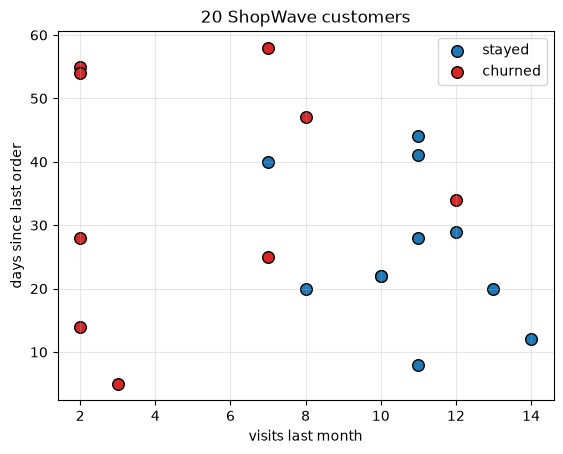

In [2]:
def plot_customers(ax=None):
    ax = ax or plt.gca()
    for label, colour, name in [(0, "tab:blue", "stayed"), (1, "tab:red", "churned")]:
        sub = cust20[cust20["churned"] == label]
        ax.scatter(sub["visits_last_month"], sub["days_since_last"], c=colour, s=70, label=name, edgecolor="k")
    ax.set_xlabel("visits last month"); ax.set_ylabel("days since last order"); ax.legend()
    return ax

plot_customers(); plt.title("20 ShopWave customers"); plt.grid(alpha=.3); plt.show()

Red and blue are not perfectly separated, but they are not random either: churners sit to the left (few visits) and towards the top (long since last order).

## 2. The baseline

Before any model: what do you get by predicting the most common class for everyone?

In [3]:
counts = y20.value_counts()
p1 = y20.mean()
print(counts.to_dict())
print(f"fraction churned p1 = {p1:.2f}")
print(f"majority-class baseline accuracy = max(p1, 1 - p1) = {max(p1, 1 - p1):.0%}  (predict 'stays' for everyone)")

{0: 11, 1: 9}
fraction churned p1 = 0.45
majority-class baseline accuracy = max(p1, 1 - p1) = 55%  (predict 'stays' for everyone)


## 3. A boundary by eye

From the README: *visits > 9 → stays, otherwise churns*. Write it as a function and score it.

In [4]:
def hand_rule(visits):
    return (visits <= 9).astype(int)          # 1 = predict churn

pred = hand_rule(cust20["visits_last_month"])
accuracy = (pred == y20).mean()
print(f"hand rule accuracy: {accuracy:.0%}")
cust20.loc[pred != y20, ["customer_id", "visits_last_month", "days_since_last", "churned"]]

hand rule accuracy: 85%


,customer_id,visits_last_month,days_since_last,churned
16,C017,8,20,0
18,C019,12,34,1
19,C020,7,40,0


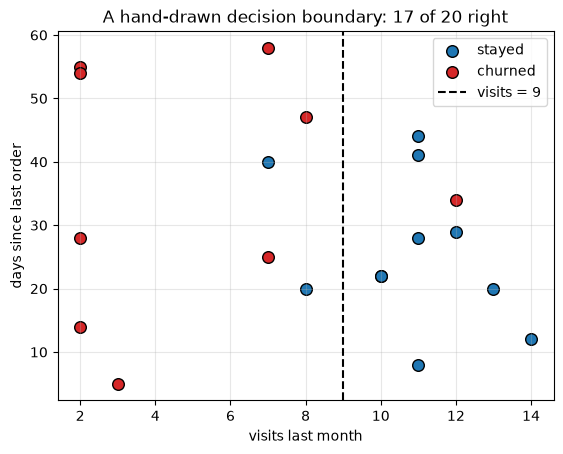

In [5]:
ax = plot_customers()
ax.axvline(9, color="k", linestyle="--", label="visits = 9"); ax.legend()
ax.set_title("A hand-drawn decision boundary: 17 of 20 right"); plt.grid(alpha=.3); plt.show()

The three misclassified customers (C017, C019, C020) are on the "wrong" side of the line. Any better boundary must bend around them, and later lessons ask whether bending is worth it.

## 4. Why not fit a line to 0/1?

Treat `churned` as a number and run the Module 02 recipe.

In [6]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(X20, y20)
lin_pred = lin.predict(X20)
print("coefficients:", lin.coef_.round(3), " intercept:", round(lin.intercept_, 3))
print(f"predictions range from {lin_pred.min():.2f} to {lin_pred.max():.2f}")
pd.DataFrame({"customer": cust20["customer_id"], "churned": y20, "line_prediction": lin_pred.round(2)}).head(8)

coefficients: [-0.088  0.005]  intercept: 1.013
predictions range from -0.15 to 1.11


,customer,churned,line_prediction
0,C001,1,1.11
1,C002,0,0.27
2,C003,0,0.25
3,C004,1,0.69
4,C005,1,0.52
5,C006,0,-0.03
6,C007,1,1.11
7,C008,0,0.25


A customer cannot be "−15% churned" or "111% churned". The line is minimising squared error to 0s and 1s, which is not the question we asked. You *could* threshold it at 0.5, but the squared-error fit is pulled around by points far from the boundary that it should not care about. Lesson 03.4 fixes this properly.

## 5. A first real classifier

`KNeighborsClassifier` predicts by looking at the nearest known customers (next lesson explains it). Note that the scikit-learn pattern is identical to regression: `fit`, `predict`, `score`.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5).fit(X20, y20)
print("predictions:", knn.predict(X20))
print(f"accuracy on the 20 customers: {knn.score(X20, y20):.0%}")

predictions: [1 0 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
accuracy on the 20 customers: 70%


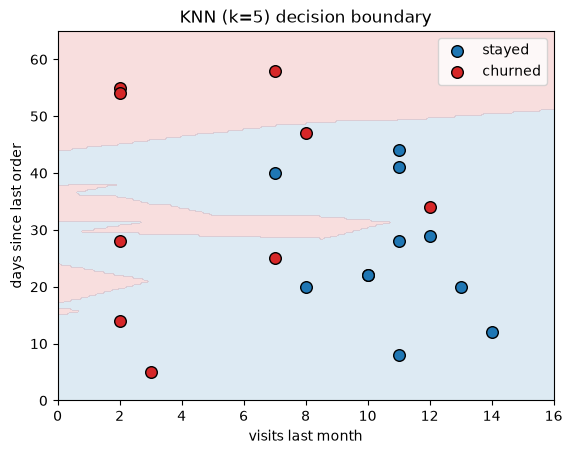

In [8]:
# draw the decision boundary: colour every point of the plane by the model's prediction
def plot_boundary(model, ax=None, title=""):
    ax = ax or plt.gca()
    vv, dd = np.meshgrid(np.linspace(0, 16, 200), np.linspace(0, 65, 200))
    grid = pd.DataFrame({"visits_last_month": vv.ravel(), "days_since_last": dd.ravel()})
    zz = model.predict(grid).reshape(vv.shape)
    ax.contourf(vv, dd, zz, levels=[-0.5, 0.5, 1.5], colors=["tab:blue", "tab:red"], alpha=.15)
    plot_customers(ax); ax.set_title(title)

plot_boundary(knn, title="KNN (k=5) decision boundary"); plt.show()

The shaded regions are the model's decision boundary: red where it would predict churn, blue where it would predict stay. Unlike your vertical line, it bends.

## 6. The real data

The customer table from lesson 01.9: features from orders before 1 September 2011, `churned = 1` if no order in September–November.

In [9]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [10]:
p1 = y_test.mean()
print(f"test customers: {len(y_test)}, churned {p1:.1%}")
print(f"baseline accuracy (predict 'stays' for all): {max(p1, 1 - p1):.1%}")

# a one-line hand rule on the strongest feature
for T in [60, 90, 120]:
    rule = (X_test["days_since_last"] > T).astype(int)
    print(f"rule 'no order for > {T} days → churn': accuracy {(rule == y_test).mean():.1%}")

test customers: 830, churned 43.6%
baseline accuracy (predict 'stays' for all): 56.4%
rule 'no order for > 60 days → churn': accuracy 60.1%
rule 'no order for > 90 days → churn': accuracy 61.7%
rule 'no order for > 120 days → churn': accuracy 64.9%


A single threshold on recency beats the baseline by about 9 points. Every model in this module has to beat **that**, not just the baseline.

## Quiz answers

1. A regression target is a number (spend); a classification target is a category (churn / stay).
2. 70%, by predicting "not spam" for every email.
3. The line (or surface) in feature space that separates where the model predicts one class from where it predicts the other.
4. Probabilities and labels live in [0, 1]; a model producing values outside it has not understood the target. Its fit is also distorted by rows far from the boundary.
5. Search all features and all thresholds systematically, in any number of dimensions, and score each candidate boundary against the known labels.

**Next:** [03.2 K-nearest neighbours by hand](../02-knn-by-hand/)